# Mathematical Modelling Group Project (MAC F314)
## Neuronal firing and excitability with the FitzHugh–Nagumo model

**Question.** How can one neuron model return to rest, fire once, or fire repeatedly?

The model has two state variables. Voltage $v$ changes quickly during a spike. Recovery $w$ changes more slowly and helps bring voltage back down. An applied current $I$ drives the system. Time, voltage, recovery and current are expressed in scaled model units. [FitzHugh’s original paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC1366333/)

## Read this notebook in three passes

| Pass | Sections | What to look for |
| --- | --- | --- |
| **1. Model and simulate** | 1–5 | What the equations mean, where the neuron can rest, and how the three voltage traces differ. |
| **2. Explain the dynamics** | 6–10 | How the phase plane, eigenvalues, current sweep, and recovery parameter explain the observed behaviour. |
| **3. Make the claims quantitative** | 11–13 | Where the firing threshold actually is, a numerically checked region around the resting state, and how the period scales with the recovery rate. |
| **4. Prepare the report figures** | 14 | How to export the same four plots as PDF and EPS. |

Run the cells from top to bottom. Each colored algorithm block describes the steps in the Python cell that follows.

## 🟦 1. Turn the equations into a Python function

$$
\frac{dv}{dt} = v-\frac{v^3}{3}-w+I,
\qquad
\frac{dw}{dt} = \varepsilon(v+a-bw).
$$

Each equation gives the **slope at the current point**. A positive slope means the variable is rising, and a negative slope means it is falling. Increasing $w$ lowers the voltage slope through the $-w$ term. We use $a=0.7$, $b=0.8$, and $\varepsilon=0.08$ so recovery changes on a slower timescale.

At $v=w=0$ and $I=0.5$, the voltage slope is $0.5$ and the recovery slope is $0.08(0.7)=0.056$. The next cell computes both values.

<pre style="background-color: #E7F1FF; color: #17365D; padding: 12px; border-left: 4px solid #2563EB;"><code>MODEL
Read the current voltage v and recovery state w.
Use the two equations to compute their slopes.
Return the voltage slope and the recovery slope.</code></pre>

In [1]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import bisect

a, b, epsilon = 0.7, 0.8, 0.08

def fhn(t, state, current, recovery_rate=epsilon):
    # solve_ivp supplies time t. The current is constant in each experiment.
    v, w = state
    dv_dt = v - v**3 / 3 - w + current
    dw_dt = recovery_rate * (v + a - b * w)
    return dv_dt, dw_dt

voltage_slope, recovery_slope = fhn(0, (0, 0), 0.5)
print(f"At v = w = 0 and I = 0.5: dv/dt = {voltage_slope:.3f}, dw/dt = {recovery_slope:.3f}")
assert abs(voltage_slope - 0.5) < 1e-12
assert abs(recovery_slope - 0.056) < 1e-12

At v = w = 0 and I = 0.5: dv/dt = 0.500, dw/dt = 0.056


## 🟩 2. Find the resting state at zero current

At an **equilibrium**, both slopes are zero. Setting the voltage slope to zero gives $w=v-v^3/3+I$. Setting the recovery slope to zero gives $w=(v+a)/b$. These two curves are called **nullclines**. Their intersection gives the equilibrium.

Substituting the second expression into the first gives

$$
\frac{b}{3}v_*^3+(1-b)v_*+a-bI=0.
$$

We first search for the root at $I=0$. Later we use the same calculation at other currents. **Bisection** repeatedly halves an interval whose endpoints have opposite signs. Each step keeps the half containing the sign change. At our chosen $b$, the cubic is strictly increasing, so the root is unique.

<pre style="background-color: #E8F7ED; color: #15432B; padding: 12px; border-left: 4px solid #27804E;"><code>REST
Find the voltage where the cubic is zero at I = 0.
Use that voltage to compute the recovery state.
Substitute both values into the original slope equations.</code></pre>

In [2]:
def equilibrium_cubic(v, current):
    return (b / 3) * v**3 + (1 - b) * v + a - b * current

def equilibrium(current):
    # The bracket [-3, 3] contains the root for the currents in this notebook.
    v_star = bisect(equilibrium_cubic, -3.0, 3.0, args=(current,))
    return v_star, (v_star + a) / b

rest_v, rest_w = equilibrium(0.0)

# Both slopes must be essentially zero at an equilibrium.
assert all(abs(slope) < 1e-10 for slope in fhn(0, (rest_v, rest_w), 0.0))
print(f"Zero-current equilibrium: v = {rest_v:.4f}, w = {rest_w:.4f}")

Zero-current equilibrium: v = -1.1994, w = -0.6243


## 🟨 3. Run three experiments

The solver uses the slopes to estimate how $v$ and $w$ change over time. We ask it to report 1,501 points from time 0 to 150. The solver uses an adaptive Runge–Kutta method. It estimates the state at the end of each step from several slope evaluations and adjusts its step size to control error. The output times are where we ask it to report the solution. [SciPy’s integration guide](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)

| Run | Initial voltage | Applied current |
| --- | --- | --- |
| Small nudge | Resting voltage plus $0.05$ | $I=0$ throughout |
| Larger nudge | Resting voltage plus $0.90$ | $I=0$ throughout |
| Sustained input | Same starting voltage as the small nudge | $I=0.50$ throughout |

In all three runs, recovery starts at the same value $w_*$. The nudges are changes to the initial voltage. The current in the third run stays on for the full simulation.

<pre style="background-color: #FFF3D4; color: #503300; padding: 12px; border-left: 4px solid #B56A00;"><code>SIMULATE
Choose the starting voltage and the constant current.
Start recovery at its zero-current equilibrium value.
Integrate the two equations and keep the resulting voltage curve.</code></pre>

In [3]:
times = [step / 10 for step in range(1501)]

def simulate(initial_state, current, sample_times, *, recovery_rate=epsilon, rtol=1e-9, atol=1e-11):
    # args keeps the current and recovery rate fixed throughout one run.
    solution = solve_ivp(
        fhn,
        (sample_times[0], sample_times[-1]),
        initial_state,
        args=(current, recovery_rate),
        t_eval=sample_times,
        method="DOP853",
        rtol=rtol,
        atol=atol,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    # Row 0 is voltage, and row 1 is recovery.
    return solution.y

near_rest = (rest_v + 0.05, rest_w)
far_from_rest = (rest_v + 0.90, rest_w)

small_nudge = simulate(near_rest, 0.0, times)
large_nudge = simulate(far_from_rest, 0.0, times)
sustained = simulate(near_rest, 0.50, times)

## 🟪 4. Plot the responses on the same scale

All three plots use the same vertical scale so their voltage peaks can be compared directly. The right panel also shows the slower recovery curve in gray. The dashed line marks the **zero-current resting voltage**, which is a reference for the two nudge experiments.

<pre style="background-color: #F1EAFE; color: #38205C; padding: 12px; border-left: 4px solid #7547B2;"><code>COMPARE
Plot time along the bottom and voltage up the side.
Use the same axis limits for each experiment.
Look for a return to rest, one spike, and repeated spikes.</code></pre>

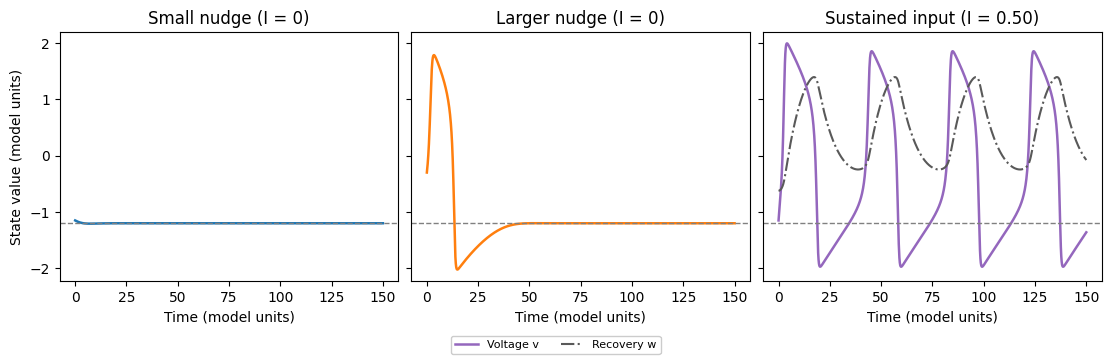

In [4]:
response_figure, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True, sharey=True, layout="constrained")
traces = [
    (small_nudge[0], "Small nudge (I = 0)", "tab:blue"),
    (large_nudge[0], "Larger nudge (I = 0)", "tab:orange"),
    (sustained[0], "Sustained input (I = 0.50)", "tab:purple"),
]

for ax, (voltage, title, color) in zip(axes, traces):
    # Shared axes make the three spike heights directly comparable.
    ax.plot(times, voltage, color=color, linewidth=1.8, label="Voltage v")
    ax.axhline(rest_v, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Time (model units)")

axes[2].plot(times, sustained[1], color="0.35", linestyle="-.", label="Recovery w")
handles, labels = axes[2].get_legend_handles_labels()
response_figure.legend(handles, labels, loc="outside lower center", ncols=2, fontsize=8, framealpha=1)
axes[0].set_ylabel("State value (model units)")
plt.show()

**Reading the plots.** The small nudge fades. The larger nudge produces a single spike and still returns to the same resting level. With current kept on, the model produces repeated spikes. The plot on the right is a starting point for studying how the long-term behaviour changes as we vary $I$.

## 🟧 5. Check the result

For these particular traces, count a spike when voltage crosses zero **upward**. Estimate the crossing time by drawing a straight line between the samples on either side of zero. Check that the two zero-current runs return to rest and that the firing result persists when we tighten the solver tolerances.

<pre style="background-color: #FFEDE3; color: #522915; padding: 12px; border-left: 4px solid #B55223;"><code>VERIFY
Count upward crossings of zero.
Check that the two nudges return to the resting voltage.
Repeat the sustained-current run with tighter tolerances.</code></pre>

In [5]:
def spike_times(sample_times, voltage):
    crossings = []
    for left_t, right_t, left_v, right_v in zip(
        sample_times, sample_times[1:], voltage, voltage[1:]
    ):
        if left_v < 0 <= right_v:
            # Interpolate where the voltage crosses zero between two samples.
            fraction = -left_v / (right_v - left_v)
            crossings.append(left_t + fraction * (right_t - left_t))
    return crossings

counts = [len(spike_times(times, trace[0])) for trace in (small_nudge, large_nudge, sustained)]
assert counts == [0, 1, 4]
assert abs(small_nudge[0, -1] - rest_v) < 1e-6
assert abs(large_nudge[0, -1] - rest_v) < 1e-6

# Compare both state variables on the same output grid.
tighter = simulate(near_rest, 0.50, times, rtol=1e-11, atol=1e-13)
largest_difference = abs(sustained - tighter).max()
assert largest_difference < 1e-6
print(f"Spike counts: {', '.join(str(count) for count in counts)}")
print(f"Numerical checks passed. Largest change with tighter tolerances: {largest_difference:.2e}")

Spike counts: 0, 1, 4
Numerical checks passed. Largest change with tighter tolerances: 4.39e-08


## 🟦 6. Draw the phase portraits

A **phase plane** puts voltage $v$ on the horizontal axis and recovery $w$ on the vertical axis. A point represents the neuron's state at one instant. Time is represented by motion along a path.

- An arrow shows which way the state moves. A positive voltage slope points to the right. A positive recovery slope points up.
- On the voltage nullcline, arrows point vertically because voltage is momentarily flat. On the recovery nullcline, arrows point horizontally.
- At their intersection, both slopes are zero. The state stays still if it starts exactly there.

We plot the zero-current excursion and the sustained-current trajectory. The arrows are scaled to similar lengths so their **direction** is easier to read.

<pre style="background-color: #DCF6FA; color: #16424C; padding: 12px; border-left: 4px solid #16869A;"><code>PHASE PLANE
Choose a grid of voltage and recovery values.
Evaluate both slopes at each point and draw an arrow.
Draw the two nullclines and mark their intersection.
Plot voltage against recovery for a simulated trajectory.</code></pre>

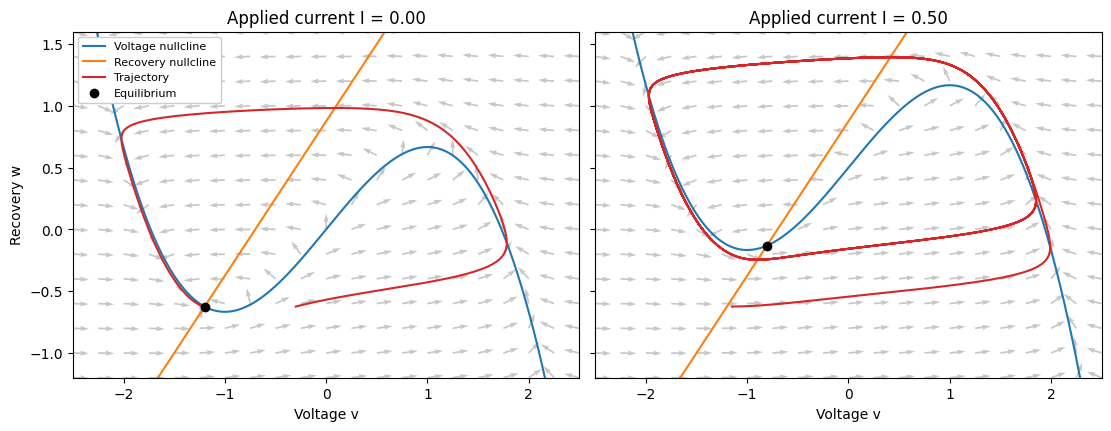

In [6]:
voltage_grid = [step / 4 for step in range(-10, 11)]
recovery_grid = [step / 5 for step in range(-6, 9)]
voltage_line = [step / 100 for step in range(-250, 251)]

phase_figure, phase_axes = plt.subplots(
    1, 2, figsize=(11, 4.2), sharey=True, layout="constrained"
)
for ax, current, trajectory in zip(phase_axes, (0.0, 0.50), (large_nudge, sustained)):
    grid_v, grid_w, arrows_v, arrows_w = [], [], [], []
    for w in recovery_grid:
        for v in voltage_grid:
            dv, dw = fhn(0, (v, w), current)
            # Rescale the arrow without changing its direction.
            length = max((dv**2 + dw**2)**0.5, 1e-12)
            grid_v.append(v)
            grid_w.append(w)
            arrows_v.append(dv / length)
            arrows_w.append(dw / length)

    ax.quiver(grid_v, grid_w, arrows_v, arrows_w, color="0.78", angles="xy")
    ax.plot(voltage_line, [v - v**3 / 3 + current for v in voltage_line], label="Voltage nullcline")
    ax.plot(voltage_line, [(v + a) / b for v in voltage_line], label="Recovery nullcline")
    ax.plot(trajectory[0], trajectory[1], color="tab:red", label="Trajectory")
    ax.scatter(*equilibrium(current), color="black", marker="o", zorder=5, label="Equilibrium")
    ax.set(title=f"Applied current I = {current:.2f}", xlabel="Voltage v",
           xlim=(-2.5, 2.5), ylim=(-1.2, 1.6))

phase_axes[0].set_ylabel("Recovery w")
phase_axes[0].legend(loc="upper left", framealpha=1, fontsize=8)
plt.show()

**Reading the phase portraits.** At zero current the trajectory makes one large excursion and comes back to the equilibrium. At $I=0.50$ the trajectory settles into a repeating loop. Each trip around the loop corresponds to one firing cycle. The graph still has an equilibrium at the nullcline intersection, so we need a stability test to explain why nearby states move away from it.

## 🟪 7. Read stability from the Jacobian

**Local stability** asks what happens after a very small nudge from equilibrium. The Jacobian describes how the slopes respond to small changes in voltage and recovery. Its rows correspond to $dv/dt$ and $dw/dt$. Its columns correspond to changing $v$ and changing $w$.

$$
J(v_*) =
egin{pmatrix}
1-v_*^2 & -1 \\
\varepsilon & -\varepsilon b
\end{pmatrix}.
$$

For example, the top-right entry is $-1$ because the voltage equation contains $-w$. The trace $T$ is the sum of the diagonal entries. The determinant $D$ is the product along the main diagonal minus the product along the other diagonal.

$$
T=1-v_*^2-\varepsilon b,
\qquad D=\varepsilon\bigl[1-b(1-v_*^2)\bigr].
$$

The eigenvalues are the two roots of $\lambda^2-T\lambda+D=0$. Their **real parts** describe whether small disturbances shrink or grow. If both real parts are negative, disturbances decay. If one is positive, the equilibrium is unstable. A real part close to zero calls for more analysis.

<pre style="background-color: #F5E8F3; color: #49213E; padding: 12px; border-left: 4px solid #994283;"><code>STABILITY
Find the equilibrium at the selected current.
Evaluate the Jacobian and compute its trace and determinant.
Use the quadratic formula and inspect both real parts.
Simulate a small nudge and compare the distance from equilibrium.</code></pre>

To check the prediction, start $0.01$ voltage units away from each equilibrium and simulate to time 150. Compare the final distance in the phase plane with the starting distance of $0.01$.

In [7]:
def jacobian(v):
    return (1 - v**2, -1), (epsilon, -epsilon * b)

def trace_and_determinant(v):
    (j11, j12), (j21, j22) = jacobian(v)
    return j11 + j22, j11 * j22 - j12 * j21

def eigenvalues(v):
    trace, determinant = trace_and_determinant(v)
    discriminant = trace**2 - 4 * determinant
    # A negative discriminant gives an imaginary square root.
    root = discriminant**0.5 if discriminant >= 0 else complex(0, (-discriminant)**0.5)
    return (trace + root) / 2, (trace - root) / 2

def largest_real_part(v):
    return max(value.real for value in eigenvalues(v))

print(f"{'I':>5}  {'v*':>9}  {'w*':>9}  {'Eigenvalues':>36}  {'Distance at t=150':>17}  Stability")
for current in (0.0, 0.50, 1.60):
    v_star, w_star = equilibrium(current)
    assert all(abs(slope) < 1e-10 for slope in fhn(0, (v_star, w_star), current))
    first, second = eigenvalues(v_star)
    rate = max(first.real, second.real)
    # Compare the final state with the same equilibrium we nudged away from.
    voltage, recovery = simulate((v_star + 0.01, w_star), current, [0.0, 150.0])
    distance = ((voltage[-1] - v_star)**2 + (recovery[-1] - w_star)**2)**0.5
    if rate < -1e-8:
        label = "stable"
        assert distance < 0.01, f"The small nudge did not decay at I={current}"
    elif rate > 1e-8:
        label = "unstable"
        assert distance > 0.01, f"The small nudge did not grow at I={current}"
    else:
        label = "linear test inconclusive"
    print(f"{current:5.2f}  {v_star:9.4f}  {w_star:9.4f}  "
          f"{first:>17.4f}, {second:>17.4f}  {distance:17.2e}  {label}")

assert largest_real_part(rest_v) < 0
assert largest_real_part(equilibrium(0.50)[0]) > 0

    I         v*         w*                           Eigenvalues  Distance at t=150  Stability
 0.00    -1.1994    -0.6243    -0.2513+0.2119j,   -0.2513-0.2119j           2.51e-10  stable
 0.50    -0.8048    -0.1311     0.1441+0.1915j,    0.1441-0.1915j           1.70e+00  unstable
 1.60     1.1043     2.2554    -0.1418+0.2719j,   -0.1418-0.2719j           1.41e-11  stable


**Interpretation.** The equilibrium is locally stable at $I=0$, unstable at $I=0.50$, and stable again at $I=1.60$. The distance from equilibrium shrinks in the stable cases and grows in the unstable case. The earlier large-nudge experiment shows that a trajectory can travel far from a stable equilibrium before returning to it.

## 🟧 8. Locate and classify the two Hopf bifurcations

A **Hopf bifurcation** occurs when an equilibrium changes stability and a small periodic orbit appears or disappears nearby. The Jacobian gives the linear part of the test. The nonlinear terms tell us whether the small orbit attracts or repels nearby trajectories.

### 8a. Locate the crossings

For a two-dimensional system, the eigenvalues are purely imaginary at $T=0$ and $D>0$. Solving the trace equation and converting the equilibrium voltage into a current gives

$$
v_H=pmsqrt{1-arepsilon b},
qquad I_H=rac{v_H+a}{b}-v_H+rac{v_H^3}{3}.
$$

A genuine crossing also needs a nonzero slope. Differentiate the equilibrium equation to obtain $dv_*/dI=b/(bv_*^2+1-b)$. Hence

$$
left.rac{dT}{dI}
ight|_{I=I_H}
=-rac{2bv_H}{bv_H^2+1-b}.
$$

Near either crossing, the eigenvalues are a complex pair with real part $T/2$. The derivative therefore tells us which side has the stable equilibrium.

### 8b. Keep the nonlinear terms

Write $x=v-v_H$, $y=w-w_H$, and $p=arepsilon b$. At $I=I_H$ the exact shifted equations are

$$
dot x=px-y+F(x),qquad dot y=arepsilon x-py,qquad
F(x)=-v_Hx^2-rac{x^3}{3}.
$$

The determinant at the crossing is $omega^2=arepsilon-p^2$. Set $X=x$, $Y=(y-px)/omega$, and rescale time as $	au=omega t$. The linear part now has unit rotation speed. In these coordinates,

$$
X'=-Y+f(X),qquad Y'=X+g(X),
qquad f=rac{F}{omega},quad g=-rac{pF}{omega^2}.
$$

Primes denote derivatives with respect to $	au$. The functions $f$ and $g$ depend only on $X$, so every term involving a $Y$ derivative vanishes from the planar first Lyapunov coefficient formula. The surviving terms, evaluated at the origin, give

$$
egin{aligned}
ell_1 &= rac{f_{XXX}-f_{XX}g_{XX}}{16}\
       &= -rac{1}{8omega}+rac{pv_H^2}{4omega^3}\
       &= rac{arepsilon(2b-1-arepsilon b^2)}{8omega^3}.
end{aligned}
$$

The sign controls the first nonlinear change in oscillation amplitude. In the local radial equation $r'=mu r+ell_1r^3+cdots$, the sign of $mu$ matches the sign of $T$. When $ell_1>0$, the small positive-radius solution exists on the $mu<0$ side and repels nearby trajectories. That is a **subcritical Hopf bifurcation**. The coefficient magnitude uses the coordinates and time scale above. Its sign determines the classification.

<pre style="background-color: #FCE8DD; color: #592D21; padding: 12px; border-left: 4px solid #B55432;"><code>HOPF CLASSIFICATION
Find the two voltages where the trace vanishes.
Compute each current, determinant, and trace slope.
Evaluate the nonlinear coefficient in unit-frequency coordinates.
Use its sign to identify the small periodic orbit's stability.</code></pre>

In [8]:
hopf_magnitude = (1 - epsilon * b)**0.5
offset = 0.004
hopf_currents = []

print(f"{'I_H':>9} {'v_H':>10} {'D':>10} {'dT/dI':>10} {'ell_1':>10}")
for v_h in (-hopf_magnitude, hopf_magnitude):
    current_h = (v_h + a) / b - v_h + v_h**3 / 3
    trace, determinant = trace_and_determinant(v_h)
    trace_slope = -2 * b * v_h / (b * v_h**2 + 1 - b)
    left_rate = largest_real_part(equilibrium(current_h - offset)[0])
    right_rate = largest_real_part(equilibrium(current_h + offset)[0])
    assert abs(trace) < 1e-12 and determinant > 0
    assert trace_slope != 0 and left_rate * right_rate < 0

    # Compute the coefficient from the derivatives, then check the simplified form.
    omega = determinant**0.5
    p = epsilon * b
    f_xx = -2 * v_h / omega
    f_xxx = -2 / omega
    g_xx = 2 * p * v_h / omega**2
    lyapunov = (f_xxx - f_xx * g_xx) / 16
    closed_form = epsilon * (2 * b - 1 - epsilon * b**2) / (8 * omega**3)
    assert abs(lyapunov - closed_form) < 1e-12
    assert lyapunov > 0

    hopf_currents.append(current_h)
    print(f"{current_h:9.6f} {v_h:+10.6f} {determinant:10.6f} {trace_slope:+10.6f} {lyapunov:+10.6f}")

assert largest_real_part(equilibrium(0.0)[0]) < 0
assert largest_real_part(equilibrium(sum(hopf_currents) / 2)[0]) > 0
assert largest_real_part(equilibrium(1.6)[0]) < 0
print("Both crossings are subcritical Hopf bifurcations.")

      I_H        v_H          D      dT/dI      ell_1
 0.331281  -0.967471   0.075904  +1.631486  +0.262432
 1.418719  +0.967471   0.075904  -1.631486  +0.262432
Both crossings are subcritical Hopf bifurcations.


**Interpretation.** The coefficient is positive at both crossings. At the lower crossing the equilibrium is stable just below $I_H$, and at the upper crossing it is stable just above $I_H$. The small unstable orbit lies on those respective stable sides. The calculation is local. The simulations below probe the larger firing trajectories and their dependence on the initial state.

## 🟨 9. Sweep the applied current

A **bifurcation** is a change in the type of behaviour when a setting varies. Here we vary the applied current and keep $a$, $b$, and $\varepsilon$ fixed. Each value of $I$ gets its own simulation from the same starting state.

The first graph compares the equilibrium voltage with the minimum and maximum voltage from time 300 to 600. When the minimum and maximum nearly coincide with the equilibrium, that run has nearly settled. A large separation shows that the voltage is still varying. The second graph shows where the equilibrium's largest eigenvalue real part changes sign. The vertical dotted lines mark the two subcritical Hopf currents calculated above. The two panels let us compare the simulated path with the stability of the equilibrium.

<pre style="background-color: #F8F1DC; color: #4F3811; padding: 12px; border-left: 4px solid #9A6D17;"><code>CURRENT SWEEP
Increase the current in small steps across separate simulations.
At each step, calculate the equilibrium and its largest eigenvalue real part.
Record the smallest and largest voltage after time 300.
Plot both summaries against current.</code></pre>

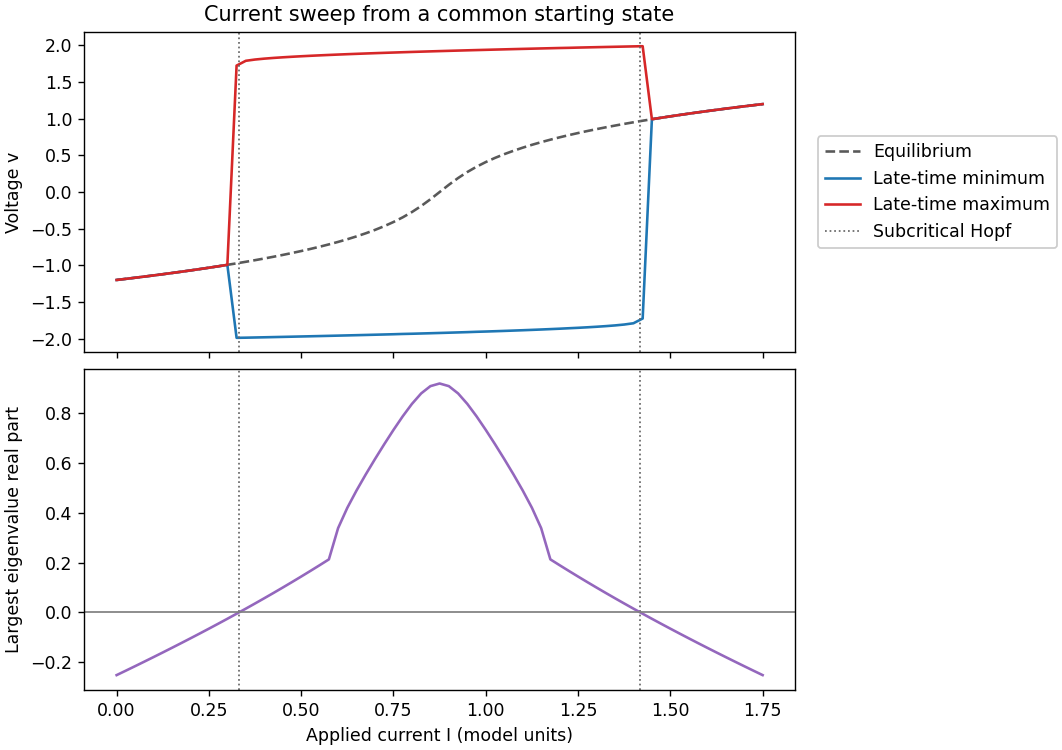

In [9]:
currents = [step / 40 for step in range(71)]
late_times = [0.0] + [300 + step / 5 for step in range(1501)]
equilibrium_voltages, real_parts = [], []
minimum_voltages, maximum_voltages = [], []

for current in currents:
    v_star, _ = equilibrium(current)
    equilibrium_voltages.append(v_star)
    real_parts.append(largest_real_part(v_star))
    # Keep time zero for the initial state, then take extrema only in the late window.
    late_voltage = simulate(near_rest, current, late_times)[0, 1:]
    minimum_voltages.append(late_voltage.min())
    maximum_voltages.append(late_voltage.max())

sweep_figure, sweep_axes = plt.subplots(2, 1, figsize=(8.5, 6.0), sharex=True, layout="constrained")
voltage_ax, stability_ax = sweep_axes
voltage_ax.plot(currents, equilibrium_voltages, color="0.35", linestyle="--", label="Equilibrium")
voltage_ax.plot(currents, minimum_voltages, color="tab:blue", label="Late-time minimum")
voltage_ax.plot(currents, maximum_voltages, color="tab:red", label="Late-time maximum")
voltage_ax.set(title="Current sweep from a common starting state", ylabel="Voltage v")
for ax in sweep_axes:
    for index, current_h in enumerate(hopf_currents):
        # Label the two lines once so the legend has a single entry.
        label = "Subcritical Hopf" if index == 0 else None
        ax.axvline(current_h, color="0.4", linestyle=":", linewidth=1, label=label)
voltage_ax.legend(framealpha=1, loc="center left", bbox_to_anchor=(1.02, 0.5))

stability_ax.plot(currents, real_parts, color="tab:purple")
stability_ax.axhline(0, color="0.5", linewidth=1)
stability_ax.set(xlabel="Applied current I (model units)", ylabel="Largest eigenvalue real part")
plt.show()

### Compare starting states near the crossings

For each bifurcation, run just below and just above its current, using an offset of $0.004$. Start each run at the equilibrium's recovery value and nudge voltage by $0.01$ or $0.80$ toward the middle of the voltage range. Compare the voltage span from time 1700 to 2000. A span near zero suggests the run has settled. A large span shows that voltage is still varying over that window.

In [10]:
refined_times = [0.0] + [1700 + step / 5 for step in range(1501)]

for v_h, current_h in zip((-hopf_magnitude, hopf_magnitude), hopf_currents):
    print(f"Near candidate I = {current_h:.6f}")
    print(f"  {'I':>9}  {'Max Re':>9}  {'Small nudge span':>17}  {'Larger nudge span':>18}")
    for current in (current_h - offset, current_h + offset):
        v_star, w_star = equilibrium(current)
        direction = 1 if v_h < 0 else -1
        spans = []
        for nudge in (0.01, 0.80):
            # Nudge toward the middle of the voltage range at each boundary.
            initial_state = (v_star + direction * nudge, w_star)
            late_voltage = simulate(initial_state, current, refined_times)[0, 1:]
            spans.append(late_voltage.max() - late_voltage.min())
        print(f"  {current:9.6f}  {largest_real_part(v_star):+9.5f}  {spans[0]:17.5f}  {spans[1]:18.5f}")

Near candidate I = 0.331281
          I     Max Re   Small nudge span   Larger nudge span
   0.327281   -0.00326            0.00008             3.73783


   0.335281   +0.00327            3.76057             3.76057
Near candidate I = 1.418719
          I     Max Re   Small nudge span   Larger nudge span


   1.414719   +0.00327            3.76057             3.76057


   1.422719   -0.00326            0.00008             3.73783


**Interpretation.** The equilibrium loses stability near $I=0.331$ and regains it near $I=1.419$. Just outside that interval, the small nudge nearly settles while the larger nudge keeps oscillating over the recorded window. This is numerical evidence that rest and repeated firing can coexist at the same current for the cases we tested.

## 🟩 10. Measure recovery sensitivity

Sensitivity analysis asks how a result changes when we change one setting. Keep the current at $I=0.50$, keep the same initial state, and change only $\varepsilon$. Compare the **mean period**, the average time between successive spikes. A longer period means slower firing.

Ignore the first 150 time units. Locate upward crossings of zero by the same rule as before, and average the time differences between crossings after the transient.

<pre style="background-color: #E1F5E8; color: #1B452D; padding: 12px; border-left: 4px solid #2C7C50;"><code>SENSITIVITY
Run the model at three recovery rates with the same current.
Discard spikes from the initial transient.
Average the time gaps between the remaining spikes.</code></pre>

 Epsilon   Late spikes   Mean period
    0.06             7        49.157
    0.08             8        39.475
    0.10             9        33.525
Sensitivity checks passed.


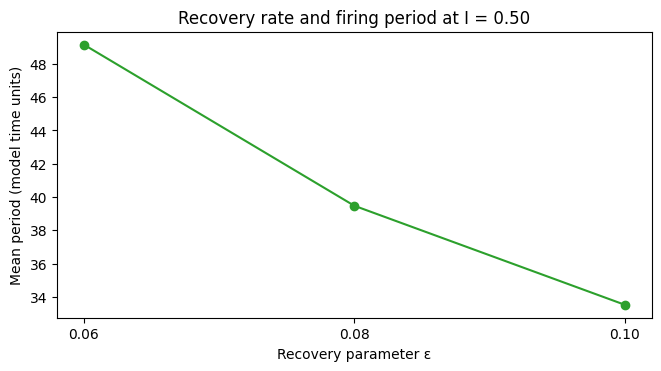

In [11]:
recovery_rates = [0.06, 0.08, 0.10]
sensitivity_times = [step / 10 for step in range(4501)]
mean_periods = []

print(f"{'Epsilon':>8}  {'Late spikes':>12}  {'Mean period':>12}")
for recovery_rate in recovery_rates:
    voltage = simulate(near_rest, 0.50, sensitivity_times, recovery_rate=recovery_rate)[0]
    # Count only crossings inside the late-time measurement window.
    crossings = [time for time in spike_times(sensitivity_times, voltage) if time >= 150]
    assert len(crossings) >= 3
    periods = [later - earlier for earlier, later in zip(crossings, crossings[1:])]
    mean_period = sum(periods) / len(periods)
    mean_periods.append(mean_period)
    print(f"{recovery_rate:8.2f}  {len(crossings):12d}  {mean_period:12.3f}")

assert mean_periods[0] > mean_periods[1] > mean_periods[2]
print("Sensitivity checks passed.")

sensitivity_figure, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
ax.plot(recovery_rates, mean_periods, marker="o", color="tab:green")
ax.set(title="Recovery rate and firing period at I = 0.50",
       xlabel="Recovery parameter ε", ylabel="Mean period (model time units)")
ax.set_xticks(recovery_rates)
plt.show()

**Interpretation.** For the three recovery rates tested at $I=0.50$, increasing $\varepsilon$ shortens the time between spikes. This describes the tested range and current.

## 🟥 11. Locate the firing threshold

Section 3 compared a $+0.05$ nudge that decays with a $+0.90$ nudge that spikes, but never asked where the boundary between them lies. **Excitability** only means something if that boundary is sharp, so we measure it.

Hold the recovery variable at its resting value, displace only the voltage, and bisect on the displacement. A decaying run never gets near $v=1$; a spike overshoots far past it, so the peak voltage is a clean classifier with no tuning.

We also solve for the **middle branch** of the cubic nullcline at the resting recovery height. The fast-subsystem picture says the threshold should sit near that branch, and comparing the two numbers tells us how good that $\varepsilon\to0$ approximation is at $\varepsilon=0.08$.

<pre style="background-color: #FDEBEC; color: #5A1016; padding: 12px; border-left: 4px solid #B3262F;"><code>FIRING THRESHOLD
Define the peak voltage reached after a given voltage offset.
Bisect on the offset until the peak jumps past v = 1.
Solve for the middle branch of the cubic at the resting recovery value.
Report the peak voltage just below and just above the located offset.</code></pre>


In [12]:
from scipy.optimize import brentq

def peak_voltage(offset, current=0.0, horizon=200.0):
    # One run from the resting recovery value, with only the voltage displaced.
    sample_times = [step / 20 for step in range(int(horizon * 20) + 1)]
    return simulate((rest_v + offset, rest_w), current, sample_times)[0].max()

# A spike overshoots far past v = 1, a decaying nudge never reaches it.
low, high = 0.05, 0.90
for _ in range(45):
    middle = (low + high) / 2
    if peak_voltage(middle) > 1.0:
        high = middle
    else:
        low = middle

threshold_offset = (low + high) / 2
threshold_voltage = rest_v + threshold_offset

# The middle branch of the cubic nullcline, at the resting recovery height.
middle_branch_v = brentq(lambda v: v - v**3 / 3 - rest_w, -1.0, 1.0)

below = peak_voltage(threshold_offset - 1e-3)
above = peak_voltage(threshold_offset + 1e-3)
assert below < 0.0 < 1.0 < above, "the response must jump across the threshold"

print(f"Critical voltage offset from rest : {threshold_offset:.4f}")
print(f"Threshold voltage                 : {threshold_voltage:.4f}")
print(f"Middle branch of the cubic at w*  : {middle_branch_v:.4f}")
print(f"Peak voltage 0.001 below threshold: {below:.4f}")
print(f"Peak voltage 0.001 above threshold: {above:.4f}")

Critical voltage offset from rest : 0.5555
Threshold voltage                 : -0.6439
Middle branch of the cubic at w*  : -0.7863
Peak voltage 0.001 below threshold: -0.3341
Peak voltage 0.001 above threshold: 1.5887


**Interpretation.** Measured at $I=0$, with recovery held at $w_*$ and a peak above $v=1$ as the spike criterion, the threshold sits at $v=-0.6439$ — a displacement of $0.5555$ from rest. Peak voltage changes sharply across it: at two test displacements, $0.001$ below and $0.001$ above the estimated threshold, the peaks are $-0.3341$ and $+1.5887$. The threshold lies $0.1424$ units to the ***right*** of the middle branch at $-0.7863$. The branch is the $\varepsilon\to0$ description of the dividing set, and at $\varepsilon=0.08$ the two differ by a resolvable amount. Bisection locates where the spike criterion flips; on its own it neither shows the response is discontinuous nor identifies the dividing set.

## 🟦 12. A numerically checked region around the resting state

The Jacobian proves that *sufficiently small* nudges decay without ever saying how small. The **Lyapunov matrix equation** makes it quantitative. Solve $A^{\mathsf{T}}P+PA=-Q$ with $Q=I$ at the resting state; because $A$ is Hurwitz the solution $P$ is unique and positive definite, and $V(z)=z^{\mathsf{T}}Pz$ is a candidate energy.

The point is to differentiate $V$ along the **full nonlinear** system, not the linearisation. Writing $\dot z=Az+g(z)$ with $g(z)=(-v_*z_1^2-z_1^3/3,\,0)$ gives

$$\dot V=-\lVert z\rVert^2+2\,(Pz)_1\Bigl(-v_*z_1^2-\tfrac{z_1^3}{3}\Bigr).$$

If $\dot V$ were negative on the whole of a sublevel set $\{V\le c\}$, that set would be forward-invariant and lie inside the basin of attraction. We do not establish that here. Marching outward along rays gives a first estimate of where $\dot V$ turns non-negative, but that march samples angles coarsely and can overshoot. So we step back to a round level just below the estimate and **sample** it densely, on the level set and across its interior — which checks the sign at the points sampled, not between them.

<pre style="background-color: #EAF1FB; color: #10283F; padding: 12px; border-left: 4px solid #1F4E79;"><code>NUMERICALLY CHECKED REGION AROUND THE RESTING STATE
Solve the Lyapunov matrix equation at the resting state.
Check that P is symmetric positive definite.
Evaluate Vdot for the full nonlinear system along rays from the origin.
Estimate the largest sublevel set on which Vdot stays negative.
Step back to a round level and sample Vdot densely on and inside it.
Convert that level back into a voltage offset.</code></pre>


In [13]:
import numpy as np
from scipy.linalg import solve_continuous_lyapunov

# A^T P + P A = -I has a unique positive-definite solution when A is Hurwitz.
A = np.array(jacobian(rest_v), dtype=float)
P = solve_continuous_lyapunov(A.T, -np.eye(2))
assert np.allclose(A.T @ P + P @ A, -np.eye(2))
assert np.all(np.linalg.eigvalsh(P) > 0)

def lyapunov_value(x, y):
    state = np.array([x, y])
    return state @ P @ state

def lyapunov_derivative(x, y):
    # The full nonlinear rate of change of V, not the linearised one.
    state = np.array([x, y])
    remainder = -rest_v * x**2 - x**3 / 3
    return state @ (A.T @ P + P @ A) @ state + 2 * (P @ state)[0] * remainder

# Step 1: a first estimate of where Vdot stops being negative, found ray by ray.
estimated_level = np.inf
for angle in np.linspace(0.0, 2 * np.pi, 721):
    for radius in np.linspace(1e-4, 3.0, 6000):
        point = (radius * np.cos(angle), radius * np.sin(angle))
        if lyapunov_derivative(*point) >= 0:
            estimated_level = min(estimated_level, lyapunov_value(*point))
            break

# Step 2: the ray march samples angles coarsely, so step back to a round level
# and check it directly on a fine grid of the level set and its interior.
tested_level = 0.2059
basis = np.linalg.cholesky(np.linalg.inv(P))   # z = sqrt(c) * basis @ unit  =>  V(z) = c

def worst_derivative_on(level, n_angles=400_001):
    angles = np.linspace(0.0, 2 * np.pi, n_angles)
    unit = np.stack([np.cos(angles), np.sin(angles)])
    points = np.sqrt(level) * (basis @ unit)
    return max(lyapunov_derivative(x, y) for x, y in points.T)

worst_boundary = worst_derivative_on(tested_level)
worst_interior = max(worst_derivative_on(tested_level * fraction, 2001)
                     for fraction in np.linspace(0.02, 1.0, 400))
assert worst_boundary < 0 and worst_interior < 0

tested_offset = np.sqrt(tested_level / P[0, 0])
assert lyapunov_value(0.05, 0.0) < tested_level < lyapunov_value(threshold_offset, 0.0)

print("P =", np.array2string(P, precision=6).replace("\n", "\n    "))
print(f"Eigenvalues of P                   : {np.linalg.eigvalsh(P).round(5)}")
print(f"Ray-march estimate of the level     : V <= {estimated_level:.6f}")
print(f"Level checked on a fine grid        : V <= {tested_level:.4f}")
print(f"  max Vdot on that level set        : {worst_boundary:+.3e}")
print(f"  max Vdot inside it (400 levels)   : {worst_interior:+.3e}")
print(f"Pure-voltage offset reached         : {tested_offset:.5f}")
print(f"Fraction of the measured threshold  : {100 * tested_offset / threshold_offset:.1f}%")
print(f"V at the 0.05 nudge used in step 3  : {lyapunov_value(0.05, 0.0):.6f}  (inside)")
print(f"V at the 0.90 nudge used in step 3  : {lyapunov_value(0.90, 0.0):.6f}  (outside)")


P = [[ 1.091492 -0.266174]
     [-0.266174 11.971474]]
Eigenvalues of P                   : [ 1.08498 11.97798]
Ray-march estimate of the level     : V <= 0.206213
Level checked on a fine grid        : V <= 0.2059
  max Vdot on that level set        : -4.052e-06
  max Vdot inside it (400 levels)   : -4.255e-06
Pure-voltage offset reached         : 0.43433
Fraction of the measured threshold  : 78.2%
V at the 0.05 nudge used in step 3  : 0.002729  (inside)
V at the 0.90 nudge used in step 3  : 0.884108  (outside)


**Interpretation.** Sampling $\dot V$ at $4\times10^5$ points of the level set $V=0.2059$ and across $400$ interior level sets, the largest value found is $-4.05\times10^{-6}$. So $\{V\le0.2059\}$ is a **numerically checked region**: at every point sampled, $\dot V$ is negative. Along the voltage axis, the numerically checked region reaches a displacement of $0.43433$, which is $78.2\%$ of the displacement $0.5555$ at which the chosen spike criterion is met. The $+0.05$ nudge of section 3 sits well inside it at $V=0.0027$.

> **What this does and does not establish.** A grid checks the sign at the points sampled, not between them. So we do **not** claim $\dot V<0$ everywhere in the region, nor that every trajectory starting inside is guaranteed to return to rest. Turning this into a guarantee needs a bound on $\dot V$ between sample points — a Lipschitz estimate over the region together with the sample spacing would do it. The margin $-4.05\times10^{-6}$ is also small, and the level is a numerical estimate rather than a proof that no larger one works.

## 🟩 13. How the firing period scales with the recovery rate

Section 10 measured the period at three recovery rates and found it falls as $\varepsilon$ rises. The **slow--fast** structure explains why, and predicts how much: almost the whole cycle is spent creeping along the outer branches of the cubic at speed proportional to $\varepsilon$, while the two jumps between branches cost $O(1)$ time. In the singular limit this gives period $\propto\varepsilon^{-1}$.

To test that, we widen the sweep by more than an order of magnitude, down to $\varepsilon=0.005$, and fit the exponent in $T\propto\varepsilon^{-\alpha}$ separately at the small and large ends. Printing $\varepsilon T$ alongside shows directly whether the product is settling to a constant.

<pre style="background-color: #E1F5E8; color: #1B452D; padding: 12px; border-left: 4px solid #2C7C50;"><code>PERIOD SCALING
Simulate at seven recovery rates over a long horizon.
Discard the approach to the limit cycle before measuring.
Average the gaps between zero crossings at each rate.
Fit the log-log slope separately at the small and large ends.</code></pre>


In [14]:
sweep_rates = [0.005, 0.01, 0.02, 0.04, 0.06, 0.08, 0.10]
sweep_periods = []
sweep_times = [step / 20 for step in range(80001)]

print(f"{'epsilon':>8}  {'mean period':>12}  {'epsilon x period':>17}")
for recovery_rate in sweep_rates:
    voltage = simulate(near_rest, 0.50, sweep_times, recovery_rate=recovery_rate)[0]
    # Discard the approach to the limit cycle before measuring the period.
    crossings = [t for t in spike_times(sweep_times, voltage) if t >= 1000.0]
    periods = [later - earlier for earlier, later in zip(crossings, crossings[1:])]
    mean_period = sum(periods) / len(periods)
    sweep_periods.append(mean_period)
    print(f"{recovery_rate:8.3f}  {mean_period:12.3f}  {recovery_rate * mean_period:17.4f}")

log_rates, log_periods = np.log(sweep_rates), np.log(sweep_periods)
slope_small = np.polyfit(log_rates[:3], log_periods[:3], 1)[0]
slope_large = np.polyfit(log_rates[-3:], log_periods[-3:], 1)[0]
assert slope_small < slope_large < 0, "the exponent must approach 1 as epsilon shrinks"

print(f"\nFitted exponent over epsilon in [0.005, 0.02] : {-slope_small:.3f}")
print(f"Fitted exponent over epsilon in [0.06, 0.10]  : {-slope_large:.3f}")
print("The singular limit predicts 1; at epsilon = 0.08 that regime is not reached.")

 epsilon   mean period   epsilon x period
   0.005       430.745             2.1537
   0.010       226.648             2.2665
   0.020       122.113             2.4423
   0.040        67.951             2.7180
   0.060        49.157             2.9494
   0.080        39.474             3.1580
   0.100        33.525             3.3525

Fitted exponent over epsilon in [0.005, 0.02] : 0.909
Fitted exponent over epsilon in [0.06, 0.10]  : 0.750
The singular limit predicts 1; at epsilon = 0.08 that regime is not reached.


**Interpretation.** The product $\varepsilon T$ is not constant over this range: it climbs steadily from $2.15$ to $3.35$. The fitted exponent is $0.909$ for $\varepsilon\in[0.005,0.02]$ and $0.750$ over $[0.06,0.10]$ — the range used in section 10. The exponent is closer to $1$ at the small end, and $\varepsilon T$ moves by a factor of $1.6$ while $T$ itself moves by a factor of $13$. Both are consistent with the slow–fast prediction $T\sim C/\varepsilon$ holding asymptotically; neither shows convergence, since the sweep stops at $\varepsilon=0.005$. So the $32\%$ drop reported in section 10 is a correct measurement taken **before** the asymptotic regime, and quoting "period $\propto1/\varepsilon$" as an exact law would be wrong at these parameters.

> **Why section 10 reports $39.475$ and this section reports $39.474$.** The two sweeps use different measurement windows and output sampling: section 10 integrates to $t=450$, samples every $0.1$ and discards crossings before $t=150$, while this one discards the first $1000$ time units. The averages are taken over different sets of cycles and each crossing is located on a different grid, so a difference of $0.001$ — about $3\times10^{-5}$ of the period — is what that alone produces.

## ⬛ 14. Export figures for the report

Set `EXPORT_FIGURES = True` and rerun this cell when you need the report figures. Each figure is saved as a vector PDF for inclusion in Overleaf and an EPS file for submission. Both versions come from the same plot.

<pre style="background-color: #E9EDF4; color: #27344A; padding: 12px; border-left: 4px solid #4A607E;"><code>REPORT FIGURES
Create the report figure folder when export is enabled.
Save each figure once as PDF and once as EPS.</code></pre>

In [ ]:
EXPORT_FIGURES = False

if EXPORT_FIGURES:
    # The standard library handles the same output folder on any platform.
    from pathlib import Path

    figure_dir = Path("report") / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    figures = {
        "voltage_responses": response_figure,
        "phase_portraits": phase_figure,
        "current_sweep": sweep_figure,
        "recovery_sensitivity": sensitivity_figure,
    }
    for name, figure in figures.items():
        figure.savefig(figure_dir / f"{name}.pdf")
        figure.savefig(figure_dir / f"{name}.eps")
    print(f"Saved {len(figures)} figures in PDF and EPS to {figure_dir}")

## Conclusions and limitations

- A small disturbance fades, a larger one gives a single excursion, and suitable sustained current gives repeated firing for the chosen model settings.
- The phase portraits and the eigenvalues explain why the zero-current run can return to rest and why the sustained-current run moves away from its equilibrium.
- The nonlinear calculation identifies two subcritical Hopf bifurcations. Each has a small unstable periodic orbit on the side where the equilibrium is stable. The current sweep and the large-nudge runs summarize selected trajectories over finite windows.
- At the tested current, faster recovery gives a shorter mean firing period. The model uses scaled units and captures qualitative behaviour of one excitable cell.

## References

- FitzHugh, R. (1961). [Impulses and Physiological States in Theoretical Models of Nerve Membrane](https://pmc.ncbi.nlm.nih.gov/articles/PMC1366333/).
- Nagumo, J., Arimoto, S., and Yoshizawa, S. (1962). [An Active Pulse Transmission Line Simulating Nerve Axon](https://doi.org/10.1109/JRPROC.1962.288235).
- Kuznetsov, Y. A. (2006). [Andronov–Hopf bifurcation](https://doi.org/10.4249/scholarpedia.1858).
- SciPy. [`solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).
- Izhikevich, E. M. (2000). [Subcritical elliptic bursting, Section 1.2](https://www.izhikevich.org/publications/subEB.pdf).
